# Stage A: Data Preparation

Comparações efetuadas com os splits train/val fornecidos. O split val serve para seleção; falta uma avaliação final independente. Os vocabulários são carregados de ficheiros; o script src/train.py usa apenas train para os aprender.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from src import utils, encoders
from src.visualization import displayRankedImageList, displayPrecisionRecallCurve
from src.visualization import RelevantVisualWordsDisplay
import os
from sklearn.metrics import confusion_matrix, precision_score, recall_score

def loadEncodingSubset(category, encoding, subset="train", root_dir="data"):
    base_dir = f"{root_dir}/encodings/{encoding}/"
    pos_file = f"{base_dir}/{category}_{subset}.npz"
    neg_file = f"{base_dir}/background_{subset}.npz"
            
    p_data = np.load(pos_file)
    p_hist, p_name = p_data['histograms'], p_data['file_names']
    p_label = np.ones(len(p_name), dtype=np.int32)

    n_data = np.load(neg_file)
    n_hist, n_name = n_data['histograms'], n_data['file_names']
    n_label = -np.ones(len(n_name), dtype=np.int32)

    hist = np.concatenate([p_hist, n_hist], axis=0)
    names = np.concatenate([p_name, n_name], axis=0)
    labels = np.concatenate([p_label, n_label], axis=0)
    
    return hist, labels, names

def get_subset(histograms, names, labels, fraction):
    num_images = len(labels)
    if np.isinf(fraction):
        num_selected = num_images
    elif fraction < 1:
        num_selected = int(np.ceil(fraction * num_images))
    else:
        num_selected = int(fraction)

    # shuffle the training data
    rng = np.random.default_rng(42)
    sel = rng.choice(num_images, size=num_selected, replace=False)
    names = [names[i] for i in sel]
    histograms = histograms[sel,:]
    labels = labels[sel]
    return histograms, names, labels

def printDatasetStats(histograms, names, labels, subset="train"):
    # count how many images are there
    print("Number of {:5s} images: {:5d} positive ({:.2%}), {:5d} negative ({:.2%}), total: {:5d}".format(subset,
        sum(labels > 0), 
        sum(labels > 0)/len(labels), 
        sum(labels < 0), 
        sum(labels < 0)/len(labels),
        len(labels)
        )
    )

def l2norm(x):
    return x/(np.sum(x**2, axis=1, keepdims=True)**0.5 + 1e-10) # l2 norm


def displayClassificationMetrics(labels, scores, threshold=0):
    # Linhas: reais; colunas: previstas; ordem: background, categoria.
    predictions = np.where(scores >= threshold, 1, -1)
    print(f"Limiar: {threshold}; ordem: [-1, +1]")
    print("Matriz de confusão:\n", confusion_matrix(labels, predictions, labels=[-1, 1]))
    print(f"Precisão: {precision_score(labels, predictions, pos_label=1, zero_division=0):.4f}")
    print(f"Recall: {recall_score(labels, predictions, pos_label=1, zero_division=0):.4f}")


In [2]:
encoding = "bovw_K512_C0"
# encoding = "vlad_K32_C80"
# encoding = "fv_K32_C80"

category = "motorbike"
# category = "aeroplane"
# category = "person"

# Load training data
histograms, labels, names = loadEncodingSubset(category, encoding, subset="train")

# Load validation data
testHistograms, testLabels, testNames = loadEncodingSubset(category, encoding, subset="val")

################################################################################
# Throw away part of the training data
################################################################################

# histograms, names, labels = get_subset(histograms, names, labels, 0.1)
# histograms, names, labels = get_subset(histograms, names, labels, 0.5)
histograms, names, labels = get_subset(histograms, names, labels, np.inf)

################################################################################
# Show some statistics about the dataset
################################################################################
print("Encoding : {}\nCategory: {}\nEncoding Size: {}".format(encoding, category, histograms.shape[1]))
printDatasetStats(histograms, names, labels, subset="train")
printDatasetStats(testHistograms, testNames, testLabels, subset="val")

################################################################################
# Vary the image representation
################################################################################
# histograms = encoders.removeSpatialInformation(histograms)
# testHistograms = encoders.removeSpatialInformation(testHistograms)

################################################################################
# Vary the classifier (Hellinger kernel)
################################################################################
# O mapa de Hellinger é comparado na Stage F.

# L2 normalize the histograms before running the linear SVM
histograms = l2norm(histograms)
testHistograms = l2norm(testHistograms)

print("Training histograms shape:", histograms.shape)
print("Validation histograms shape:", testHistograms.shape)


Encoding : bovw_K512_C0
Category: motorbike
Encoding Size: 2048
Number of train images:   120 positive (10.54%),  1019 negative (89.46%), total:  1139
Number of val   images:   125 positive (10.40%),  1077 negative (89.60%), total:  1202
Training histograms shape: (1139, 2048)
Validation histograms shape: (1202, 2048)


## Stage A — Comparação de BoVW

Comparação de K=256, 512 e 1024, com histograma global e divisão espacial 2×2. Normalização L2 e SVM com C=10; treino em `train` e avaliação em `val`.


In [3]:
from pathlib import Path
from time import perf_counter
import platform
import sys
import pandas as pd
import sklearn
from sklearn.svm import LinearSVC
from sklearn.metrics import average_precision_score, precision_recall_curve
from IPython.display import display

STAGE_A_ROOT = Path("data")
STAGE_A_SEED = 42
STAGE_A_CATEGORY = category
STAGE_A_KS = (256, 512, 1024)
STAGE_A_C = 10.0
# Parâmetros explícitos; mantém utils.py original.
SVM_MAX_ITER = 200000
SVM_TOL = 1e-4
stage_a_rng = np.random.default_rng(STAGE_A_SEED)

print({"python": sys.version.split()[0], "numpy": np.__version__,
       "sklearn": sklearn.__version__, "platform": platform.platform(),
       "seed": STAGE_A_SEED, "category": STAGE_A_CATEGORY,
       "C": STAGE_A_C, "normalization": "L2", "fit": "train", "evaluate": "val"})

{'python': '3.11.17', 'numpy': '2.4.6', 'sklearn': '1.9.1', 'platform': 'Linux-7.0.0-38-generic-x86_64-with-glibc2.43', 'seed': 42, 'category': 'motorbike', 'C': 10.0, 'normalization': 'L2', 'fit': 'train', 'evaluate': 'val'}


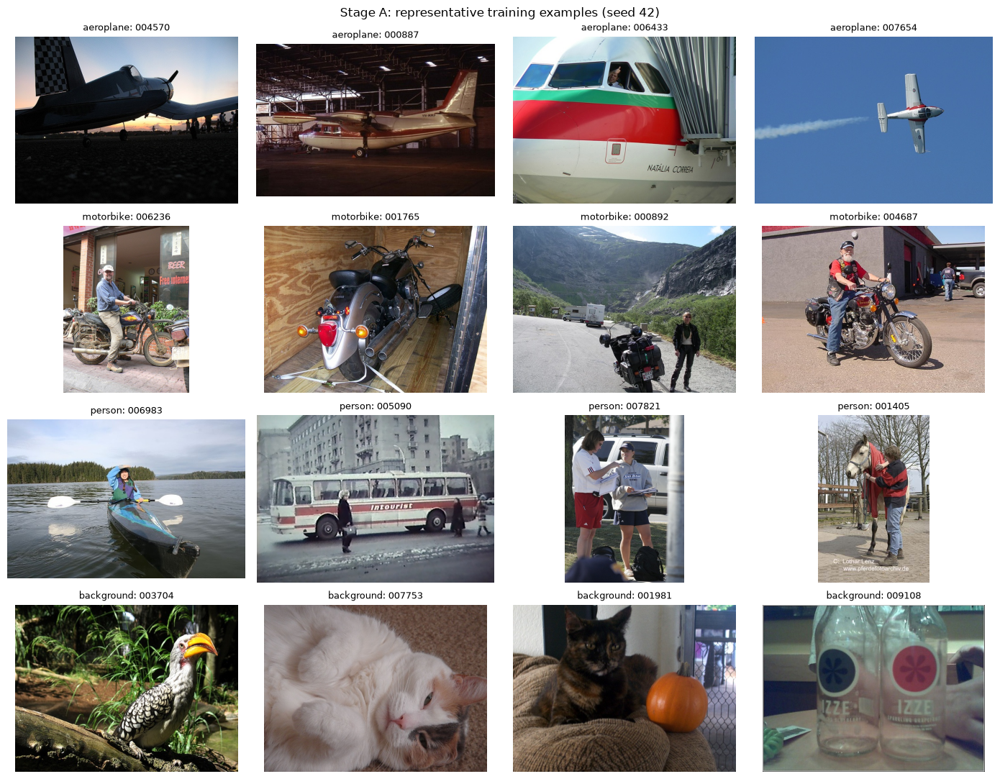

In [4]:
stage_a_categories = ("aeroplane", "motorbike", "person", "background")
fig, axes = plt.subplots(len(stage_a_categories), 4, figsize=(14, 11))
for row, cat in enumerate(stage_a_categories):
    archive = STAGE_A_ROOT / "encodings/bovw_K512_C0" / f"{cat}_train.npz"
    with np.load(archive) as data:
        image_names = data["file_names"].astype(str)
    chosen = stage_a_rng.choice(image_names, size=min(4, len(image_names)), replace=False)
    for col, ax in enumerate(axes[row]):
        ax.axis("off")
        if col < len(chosen):
            image_path = STAGE_A_ROOT / "images" / f"{chosen[col]}.jpg"
            ax.imshow(plt.imread(image_path))
            ax.set_title(f"{cat}: {chosen[col]}", fontsize=9)
fig.suptitle("Stage A: representative training examples (seed 42)")
fig.tight_layout()
plt.show()

In [5]:
stage_a_encoder_rows = []
for k in STAGE_A_KS:
    encoder_path = STAGE_A_ROOT / "encoders" / f"bovw_K{k}_C0.npz"
    with np.load(encoder_path, allow_pickle=True) as cfg:
        row = {"K": k, "encoder_KiB": encoder_path.stat().st_size / 1024}
        for key in ("num_words", "pca_dim", "seed", "num_images", "num_samples"):
            row[key] = cfg[key].item() if key in cfg else "not recorded"
        assert int(cfg["num_words"]) == k
    stage_a_encoder_rows.append(row)
display(pd.DataFrame(stage_a_encoder_rows))

FileNotFoundError: [Errno 2] No such file or directory: 'data/encoders/bovw_K256_C0.npz'

In [6]:
def stage_a_representation(raw_histograms, k, spatial):
    raw = np.asarray(raw_histograms, dtype=np.float64)
    if raw.ndim != 2 or raw.shape[1] != 4 * k:
        raise ValueError(f"Expected (N, {4*k}) tile-major BoVW counts, got {raw.shape}")
    if not np.isfinite(raw).all() or (raw < 0).any():
        raise ValueError("BoVW counts must be finite and nonnegative")
    counts = raw if spatial else raw.reshape(len(raw), 4, k).sum(axis=1)
    return l2norm(counts)

stage_a_rows = []
stage_a_curves = {}
stage_a_reference = {}
stage_a_baseline = None
for k in STAGE_A_KS:
    encoding_name = f"bovw_K{k}_C0"
    started = perf_counter()
    train_raw, train_y, train_names = loadEncodingSubset(
        STAGE_A_CATEGORY, encoding_name, subset="train", root_dir=str(STAGE_A_ROOT))
    val_raw, val_y, val_names = loadEncodingSubset(
        STAGE_A_CATEGORY, encoding_name, subset="val", root_dir=str(STAGE_A_ROOT))
    load_seconds = perf_counter() - started
    # Check fixed splits.
    for subset, image_names, y in (("train", train_names, train_y), ("val", val_names, val_y)):
        if len(set(image_names)) != len(image_names):
            raise ValueError(f"Duplicate images in {subset}")
        if subset not in stage_a_reference:
            stage_a_reference[subset] = (image_names.copy(), y.copy())
        else:
            np.testing.assert_array_equal(image_names, stage_a_reference[subset][0])
            np.testing.assert_array_equal(y, stage_a_reference[subset][1])
    assert not set(train_names).intersection(val_names), "Train/validation overlap"
    for spatial in (False, True):
        representation = "2x2" if spatial else "global"
        started = perf_counter()
        x_train = stage_a_representation(train_raw, k, spatial)
        x_val = stage_a_representation(val_raw, k, spatial)
        preprocessing_seconds = perf_counter() - started
        if encoding_name == encoding and spatial:
            stage_a_baseline = (x_train, train_y, train_names, x_val, val_y, val_names)
        clf = LinearSVC(C=STAGE_A_C, loss="hinge", dual=True,
                        max_iter=SVM_MAX_ITER, tol=SVM_TOL, random_state=STAGE_A_SEED)
        started = perf_counter()
        clf.fit(x_train, train_y)
        fit_seconds = perf_counter() - started
        started = perf_counter()
        val_scores = clf.decision_function(x_val)
        inference_seconds = perf_counter() - started
        train_scores = clf.decision_function(x_train)
        ap = average_precision_score(val_y, val_scores, pos_label=1)
        precision, recall, _ = precision_recall_curve(val_y, val_scores, pos_label=1)
        stage_a_curves[(k, representation)] = (precision, recall, ap)
        top = min(36, len(val_y))
        top_indices = np.argsort(-val_scores, kind="stable")[:top]
        stage_a_rows.append({
            "K": k, "representation": representation, "dimensions": x_train.shape[1],
            "train_AP": average_precision_score(train_y, train_scores, pos_label=1),
            "val_AP": ap, "val_P@36": np.mean(val_y[top_indices] == 1),
            "load_s": load_seconds, "preprocess_s": preprocessing_seconds,
            "svm_fit_s": fit_seconds, "val_score_ms_per_image": 1000*inference_seconds/len(val_y),
            "feature_KiB_per_image_float64": x_train.shape[1]*8/1024,
            "svm_iterations": int(clf.n_iter_),
        })

stage_a_results = pd.DataFrame(stage_a_rows)
display(stage_a_results.round(5))

# Reuse the selected representation in Stages B/C.
if stage_a_baseline is None:
    histograms, labels, names = loadEncodingSubset(category, encoding, subset="train")
    testHistograms, testLabels, testNames = loadEncodingSubset(category, encoding, subset="val")
    histograms = l2norm(histograms)
    testHistograms = l2norm(testHistograms)
else:
    histograms, labels, names, testHistograms, testLabels, testNames = stage_a_baseline

printDatasetStats(histograms, names, labels, subset="train")
printDatasetStats(testHistograms, testNames, testLabels, subset="val")

FileNotFoundError: [Errno 2] No such file or directory: 'data/encodings/bovw_K256_C0//motorbike_train.npz'

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for (k, representation), (precision, recall, ap) in stage_a_curves.items():
    axes[0].step(recall, precision, where="post", label=f"K={k}, {representation}, AP={ap:.3f}")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Validation precision-recall",
            xlim=(0, 1), ylim=(0, 1.02))
axes[0].legend(fontsize=8)
for representation, group in stage_a_results.groupby("representation"):
    axes[1].plot(group["K"], group["val_AP"], "o-", label=representation)
axes[1].set(xlabel="Vocabulary size K", ylabel="Validation AP",
            title="Vocabulary size and spatial information", xticks=list(STAGE_A_KS))
axes[1].legend()
fig.tight_layout()
plt.show()

# Stage B: Treino do classificador

SVM linear com C fixo; avaliação e escolha das representações no split val.

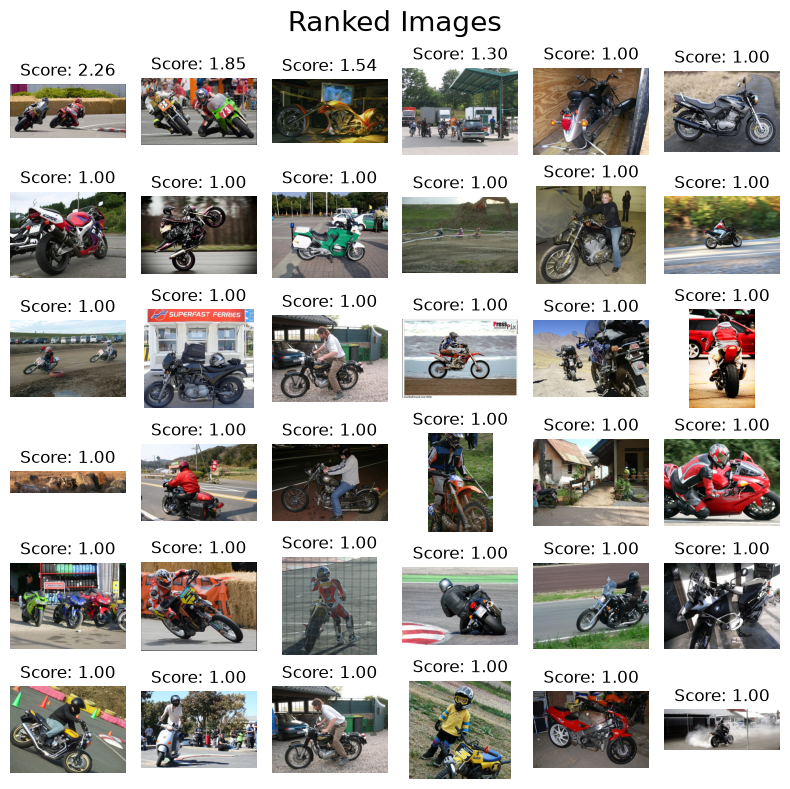

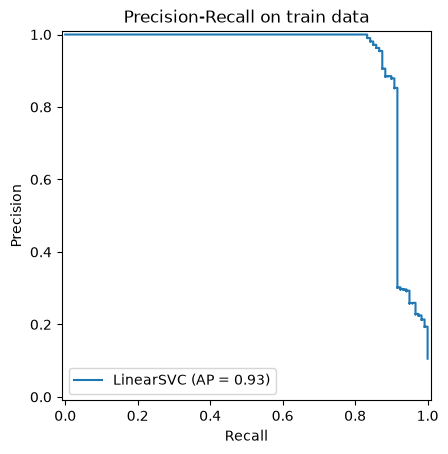

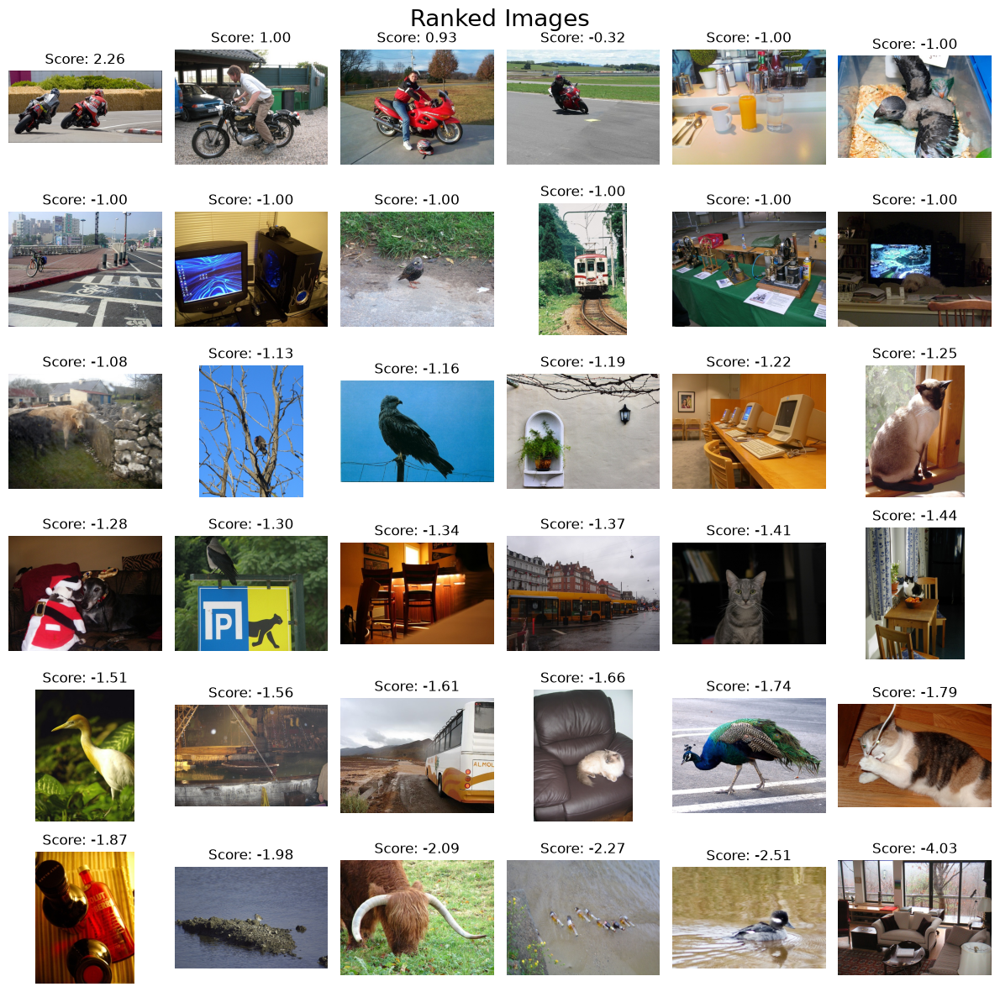

In [7]:
# Configure and train the linear SVM
W, b = utils.train_svm(
    histograms, labels, C=STAGE_A_C, max_iter=SVM_MAX_ITER,
    tol=SVM_TOL, seed=STAGE_A_SEED)

# # Evaluate the scores on the training data
scores = (W @ histograms.T  + b)

# Visualize the ranked list of images
full_paths = [f"data/images/{name}.jpg" for name in names]
displayRankedImageList(scores, full_paths, uniform=False, figzize=(8, 8))

# Visualize the precision-recall curve
_ = displayPrecisionRecallCurve(labels, scores, title="Precision-Recall on train data")

# Exemplos distribuídos por todo o ranking, incluindo os scores mais baixos
displayRankedImageList(scores, full_paths, uniform=True, figzize=(12, 12))

max_idx = np.argmax(scores)
img_file = f"data/images/{names[max_idx]}.jpg"

In [8]:
max_idx = np.argmax(scores)
image_name = names[max_idx]

# Palavras relevantes numa imagem de treino.
assert "bovw" in encoding, "only works for BOVW encoding"
encoder = encoders.ImageEncoder(f"data/encoders/{encoding}.npz")
img_file = "data/images/{}.jpg".format(names[max_idx])
img = encoders.standarizeImage(img_file)
rvwdisplay = RelevantVisualWordsDisplay(img, W, encoder, hellinger=False)
import ipywidgets as widgets
@widgets.interact(rank=(0, len(rvwdisplay)-1))
def display_relevant_visual_words(rank=0):
    rvwdisplay.plot(rank, figsize=(12, 8))


Number of keypoints: 25111 Descriptor dimension: 128


interactive(children=(IntSlider(value=0, description='rank', max=511), Output()), _dom_classes=('widget-intera…

# Stage C: Avaliação em validação

O split val é usado nas comparações; estes resultados não são um teste final independente.

Correctly retrieved in the top 36: 29


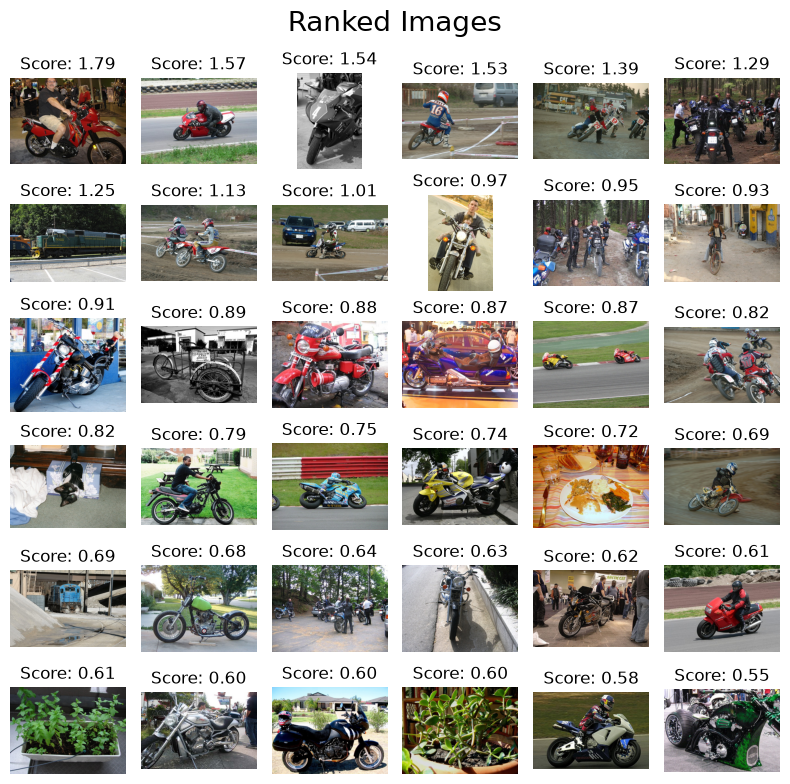

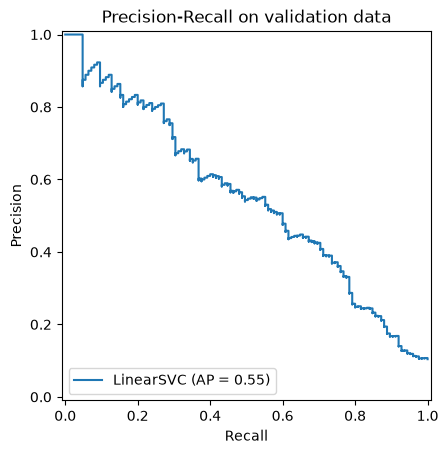

Average Precision (AP) on validation data: 0.5506
Limiar: 0; ordem: [-1, +1]
Matriz de confusão:
 [[1047   30]
 [  79   46]]
Precisão: 0.6053
Recall: 0.3680


In [9]:

# Avalia o SVM em validação
testScores = W @ testHistograms.T + b
# testScores = svm.decision_function(testHistograms)

# Print Results
perm = np.argsort(testScores)[::-1]
print('Correctly retrieved in the top 36: {:d}'.format(sum(testLabels[perm[:36]] > 0)))

# Visualize the ranked list of images
full_paths = [f"data/images/{name}.jpg" for name in testNames]
displayRankedImageList(testScores, full_paths, uniform=False, figzize=(8, 8))

# Visualize the precision-recall curve
*_, ap= displayPrecisionRecallCurve(testLabels, testScores, title="Precision-Recall on validation data")
print(f"Average Precision (AP) on validation data: {ap:.4f}")
displayClassificationMetrics(testLabels, testScores)


# Stage D: Outras categorias

motorbike


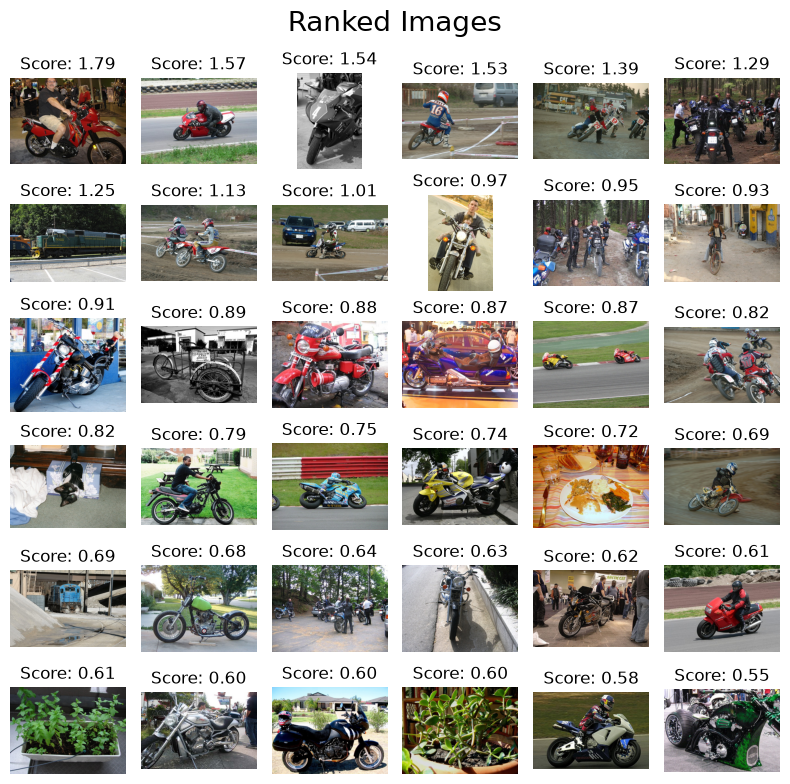

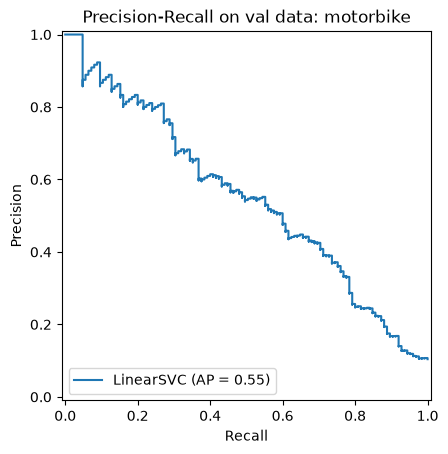

Limiar: 0; ordem: [-1, +1]
Matriz de confusão:
 [[1047   30]
 [  79   46]]
Precisão: 0.6053
Recall: 0.3680
aeroplane


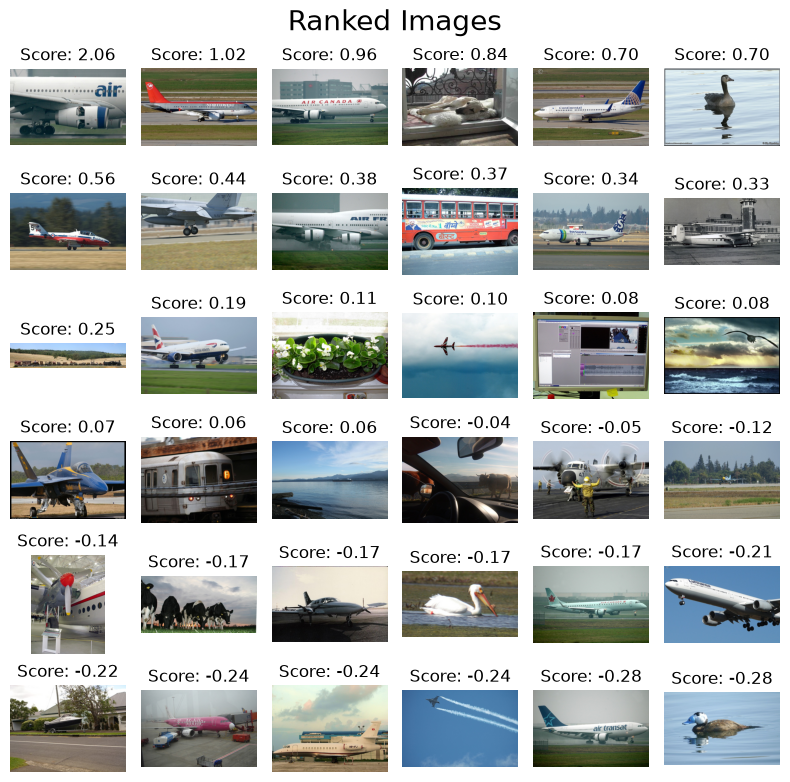

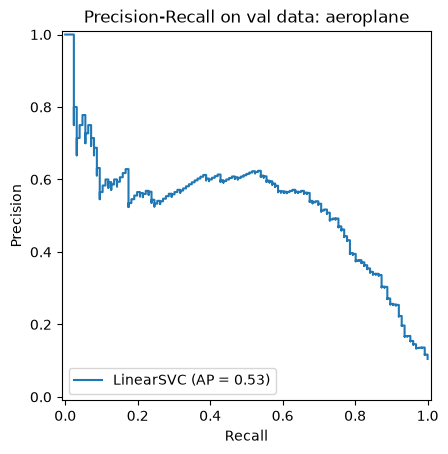

Limiar: 0; ordem: [-1, +1]
Matriz de confusão:
 [[1068    9]
 [ 114   12]]
Precisão: 0.5714
Recall: 0.0952
person


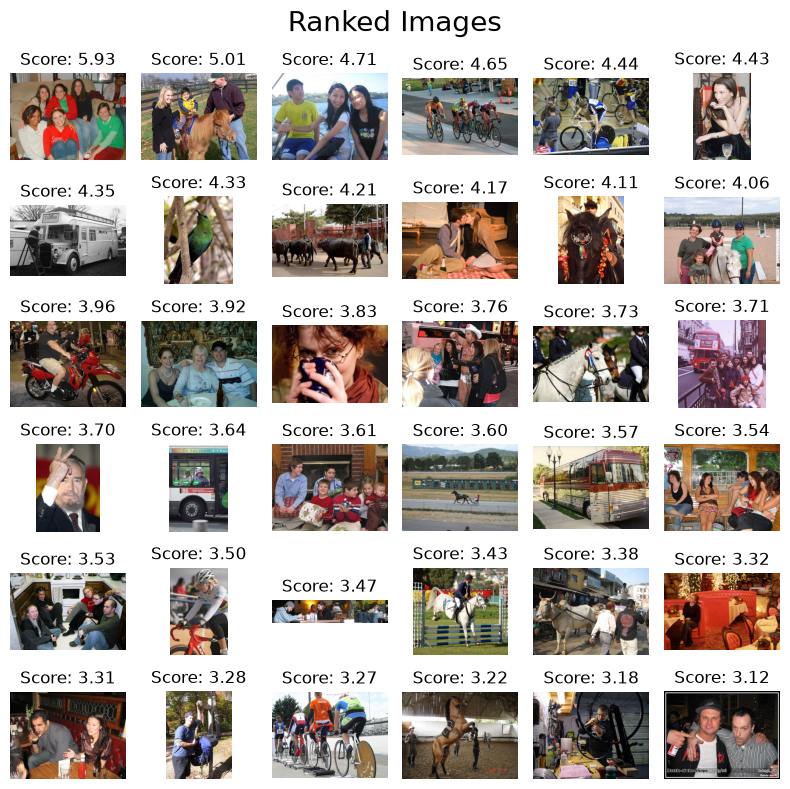

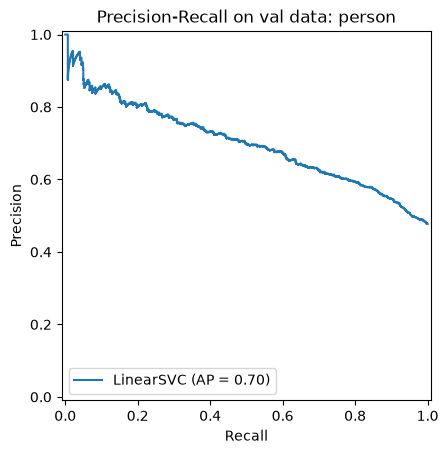

Limiar: 0; ordem: [-1, +1]
Matriz de confusão:
 [[805 272]
 [415 568]]
Precisão: 0.6762
Recall: 0.5778
horse


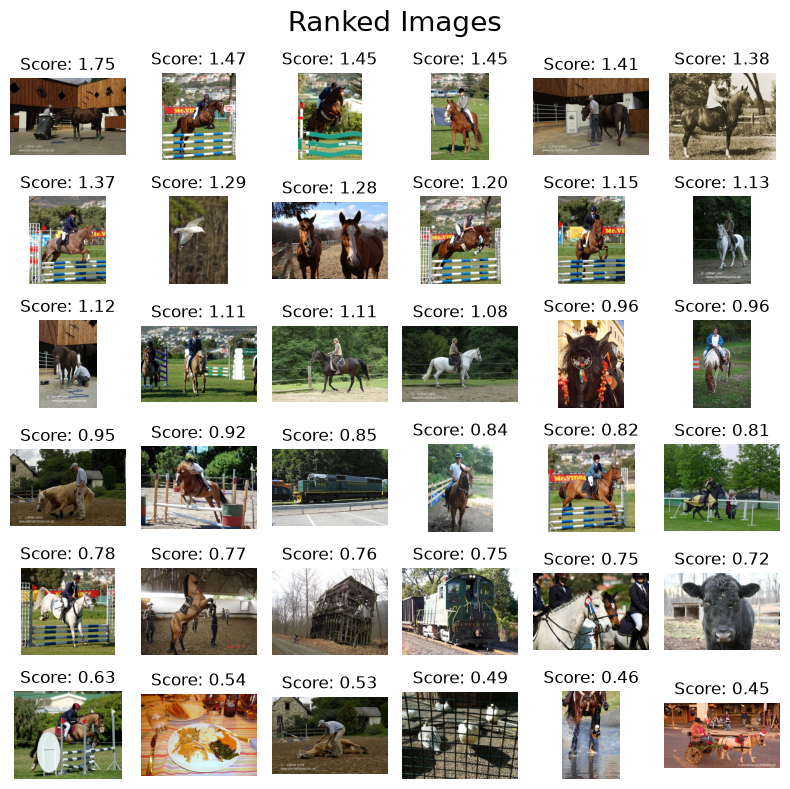

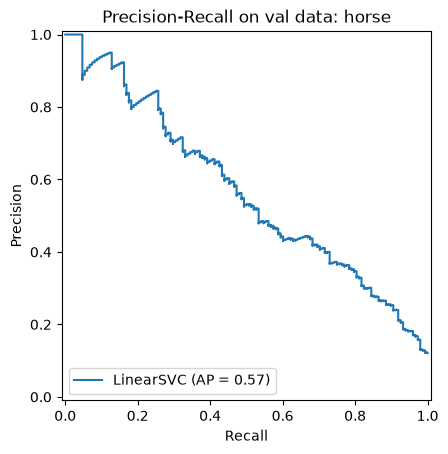

Limiar: 0; ordem: [-1, +1]
Matriz de confusão:
 [[1054   23]
 [  99   49]]
Precisão: 0.6806
Recall: 0.3311
car


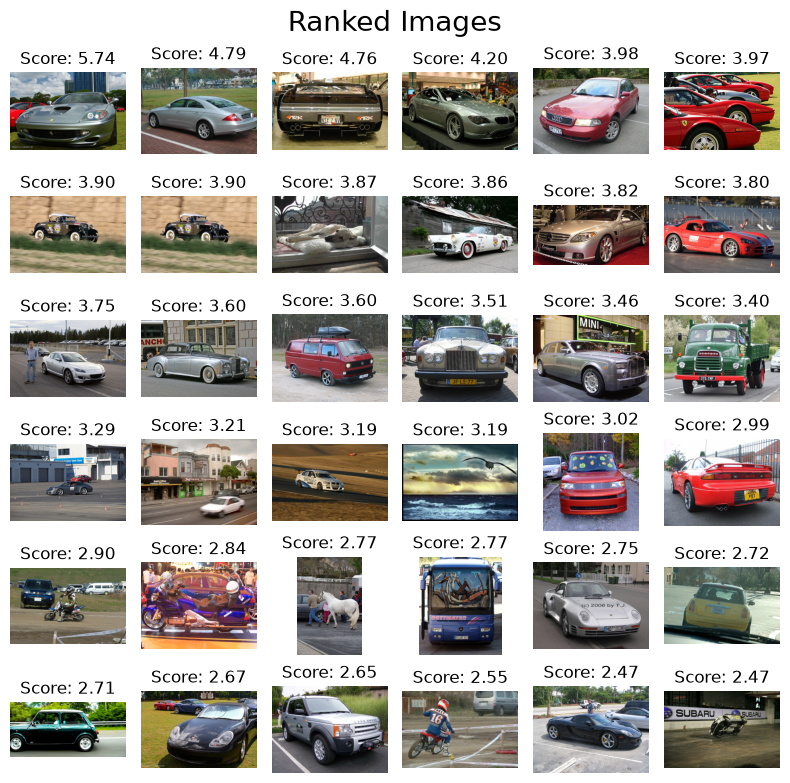

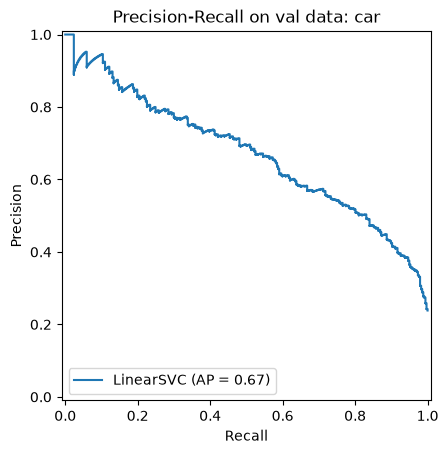

Limiar: 0; ordem: [-1, +1]
Matriz de confusão:
 [[996  81]
 [164 173]]
Precisão: 0.6811
Recall: 0.5134


,category,train_positive,val_positive,val_AP
0,motorbike,120,125,0.5506
1,aeroplane,112,126,0.5270
2,person,1025,983,0.7003
3,horse,139,148,0.5692
4,car,376,337,0.6716


mAP (val): 0.6037


In [10]:
# Mantém a configuração das etapas anteriores.
stage_d_rows = []
for stage_d_category in ("motorbike", "aeroplane", "person", "horse", "car"):
    stage_d_train, stage_d_labels, _ = loadEncodingSubset(
        stage_d_category, encoding, subset="train")
    stage_d_val, stage_d_val_labels, stage_d_names = loadEncodingSubset(
        stage_d_category, encoding, subset="val")
    stage_d_train = l2norm(stage_d_train)
    stage_d_val = l2norm(stage_d_val)

    stage_d_w, stage_d_b = utils.train_svm(
        stage_d_train, stage_d_labels, C=STAGE_A_C, max_iter=SVM_MAX_ITER,
        tol=SVM_TOL, seed=STAGE_A_SEED)
    stage_d_scores = stage_d_w @ stage_d_val.T + stage_d_b

    # Mostra o ranking e a curva por categoria.
    print(stage_d_category)
    stage_d_paths = [f"data/images/{name}.jpg" for name in stage_d_names]
    displayRankedImageList(stage_d_scores, stage_d_paths, uniform=False, figzize=(8, 8))
    *_, stage_d_ap = displayPrecisionRecallCurve(
        stage_d_val_labels, stage_d_scores,
        title=f"Precision-Recall on val data: {stage_d_category}")
    displayClassificationMetrics(stage_d_val_labels, stage_d_scores)
    stage_d_rows.append({
        "category": stage_d_category,
        "train_positive": int(np.sum(stage_d_labels > 0)),
        "val_positive": int(np.sum(stage_d_val_labels > 0)),
        "val_AP": stage_d_ap,
    })

stage_d_results = pd.DataFrame(stage_d_rows)
display(stage_d_results.round(4))
print(f"mAP (val): {stage_d_results['val_AP'].mean():.4f}")


# Stage E: Normalização e informação espacial

/home/luis/Desktop/iacv_labs/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


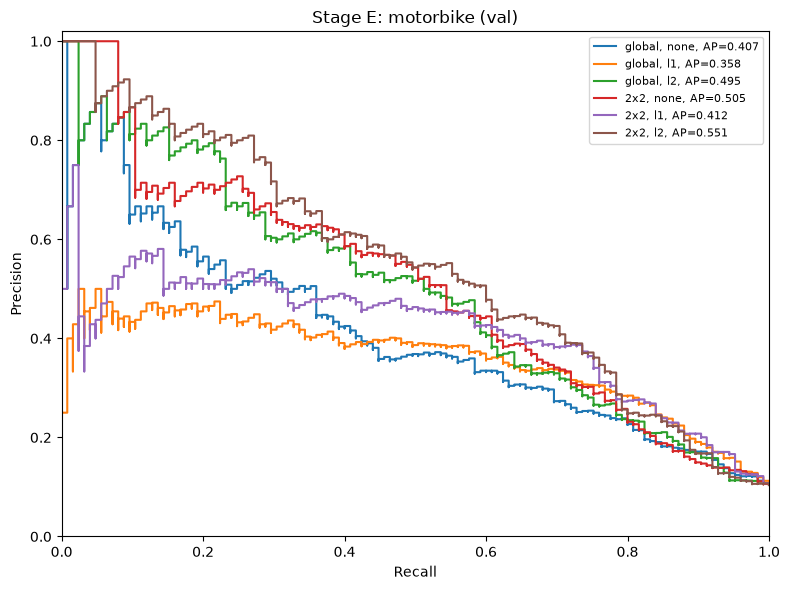

,category,representation,normalization,dimensions,train_AP,val_AP,svm_iterations,converged
0,motorbike,global,none,512,1.0000,0.4074,200000,False
1,motorbike,global,l1,512,0.7494,0.3579,33513,True
2,motorbike,global,l2,512,0.8504,0.4954,3496,True
3,motorbike,2x2,none,2048,1.0000,0.5050,47195,True
4,motorbike,2x2,l1,2048,0.8566,0.4120,16460,True
5,motorbike,2x2,l2,2048,0.9320,0.5506,1800,True


Melhor configuração convergida em validação:


,category,representation,normalization,dimensions,train_AP,val_AP,svm_iterations,converged
5,motorbike,2x2,l2,2048,0.931976,0.550632,1800,True


In [11]:
from sklearn.preprocessing import normalize

# Recarrega as contagens sem normalização.
stage_e_train, stage_e_labels, _ = loadEncodingSubset(category, encoding, subset="train")
stage_e_val, stage_e_val_labels, _ = loadEncodingSubset(category, encoding, subset="val")
stage_e_k = stage_e_train.shape[1] // 4
stage_e_rows = []

fig, ax = plt.subplots(figsize=(8, 6))
for stage_e_spatial in (False, True):
    # Usa a mesma agregação global da Stage A.
    stage_e_counts = [
        raw if stage_e_spatial else raw.reshape(len(raw), 4, stage_e_k).sum(axis=1)
        for raw in (stage_e_train, stage_e_val)
    ]
    stage_e_representation = "2x2" if stage_e_spatial else "global"

    for stage_e_norm in ("none", "l1", "l2"):
        stage_e_x, stage_e_x_val = [
            raw if stage_e_norm == "none" else
            (l2norm(raw) if stage_e_norm == "l2" else normalize(raw, norm="l1"))
            for raw in stage_e_counts
        ]
        stage_e_clf = LinearSVC(
            C=STAGE_A_C, loss="hinge", dual=True, max_iter=SVM_MAX_ITER,
            tol=SVM_TOL, random_state=STAGE_A_SEED)
        stage_e_clf.fit(stage_e_x, stage_e_labels)

        stage_e_scores = stage_e_clf.decision_function(stage_e_x_val)
        stage_e_ap = average_precision_score(stage_e_val_labels, stage_e_scores)
        stage_e_precision, stage_e_recall, _ = precision_recall_curve(
            stage_e_val_labels, stage_e_scores)

        ax.step(
            stage_e_recall, stage_e_precision, where="post",
            label=f"{stage_e_representation}, {stage_e_norm}, AP={stage_e_ap:.3f}"
        )
        stage_e_rows.append({
            "category": category,
            "representation": stage_e_representation,
            "normalization": stage_e_norm,
            "dimensions": stage_e_x.shape[1],
            "train_AP": average_precision_score(
                stage_e_labels, stage_e_clf.decision_function(stage_e_x)),
            "val_AP": stage_e_ap,
            "svm_iterations": int(stage_e_clf.n_iter_),
            "converged": stage_e_clf.n_iter_ < stage_e_clf.max_iter,
        })

ax.set(
    xlabel="Recall", ylabel="Precision",
    title=f"Stage E: {category} (val)",
    xlim=(0, 1), ylim=(0, 1.02)
)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

stage_e_results = pd.DataFrame(stage_e_rows)
display(stage_e_results.round(4))

# Seleciona apenas modelos que convergiram.
stage_e_valid = stage_e_results[stage_e_results["converged"]]
if not stage_e_valid.empty:
    stage_e_best = stage_e_valid.loc[stage_e_valid["val_AP"].idxmax()]
    print("Melhor configuração convergida em validação:")
    display(stage_e_best.to_frame().T)
else:
    print("Nenhum modelo convergiu; aumentar max_iter antes de comparar.")

# Stage F: Mapa de Hellinger

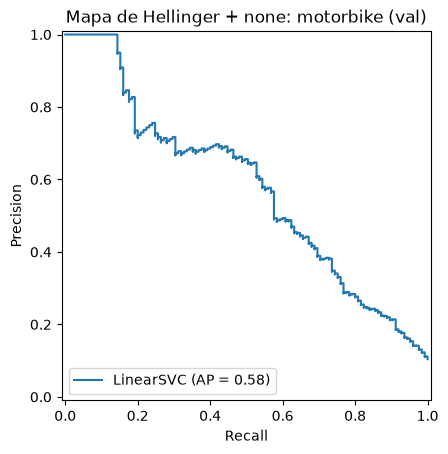

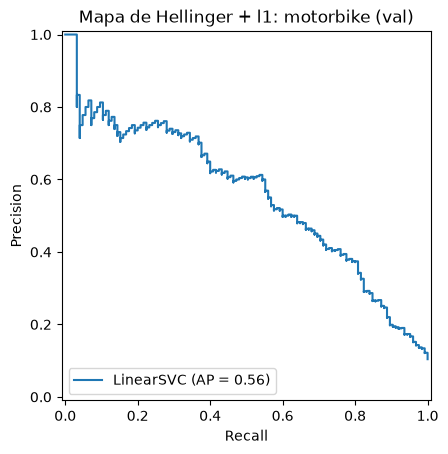

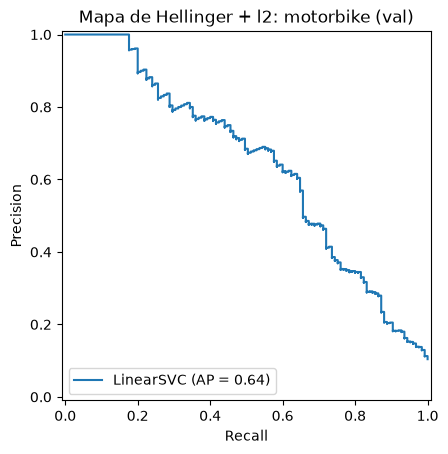

,method,train_AP,val_AP,svm_iterations,converged
0,linear + l2,0.9320,0.5506,1800,True
1,Hellinger + none,1.0000,0.5767,309,True
2,Hellinger + l1,0.9495,0.5582,32128,True
3,Hellinger + l2,0.9987,0.6430,513,True


In [12]:
from sklearn.base import clone

assert category == "motorbike" and "bovw" in encoding
# Reutiliza as contagens e a configuração da Stage E (2×2).
stage_f_sqrt = [np.sqrt(raw) for raw in (stage_e_train, stage_e_val)]
stage_f_rows = []
for stage_f_norm in ("none", "l1", "l2"):
    stage_f_x, stage_f_x_val = [
        raw if stage_f_norm == "none" else
        (l2norm(raw) if stage_f_norm == "l2" else normalize(raw, norm="l1"))
        for raw in stage_f_sqrt
    ]
    stage_f_clf = clone(stage_e_clf)
    stage_f_clf.fit(stage_f_x, stage_e_labels)
    stage_f_scores = stage_f_clf.decision_function(stage_f_x_val)
    *_, stage_f_ap = displayPrecisionRecallCurve(
        stage_e_val_labels, stage_f_scores,
        title=f"Mapa de Hellinger + {stage_f_norm}: {category} (val)")
    stage_f_rows.append({
        "method": f"Hellinger + {stage_f_norm}",
        "train_AP": average_precision_score(
            stage_e_labels, stage_f_clf.decision_function(stage_f_x)),
        "val_AP": stage_f_ap,
        "svm_iterations": int(stage_f_clf.n_iter_),
        "converged": stage_f_clf.n_iter_ < stage_f_clf.max_iter,
    })

# Raiz quadrada seguida de L2 equivale à raiz de L1 (Hellinger).
stage_f_results = pd.DataFrame(stage_f_rows)
stage_f_baseline = stage_e_results.loc[
    (stage_e_results["representation"] == "2x2") &
    (stage_e_results["normalization"] == "l2"),
    ["train_AP", "val_AP", "svm_iterations", "converged"]
].assign(method="linear + l2")
stage_f_results = pd.concat([stage_f_baseline, stage_f_results], ignore_index=True)
display(stage_f_results[["method", "train_AP", "val_AP", "svm_iterations", "converged"]].round(4))


# Stage G: Número de imagens de treino

,method,fraction,n_train,n_positive,val_AP_mean,val_AP_std,converged
0,Hellinger + L2,0.10,114,12,0.3333,0.0708,True
1,Hellinger + L2,0.25,285,30,0.4598,0.0355,True
2,Hellinger + L2,0.50,570,60,0.5479,0.0453,True
3,Hellinger + L2,1.00,1139,120,0.6430,0.0000,True
4,Linear + L2,0.10,114,12,0.2797,0.0614,True
5,Linear + L2,0.25,285,30,0.3818,0.0358,True
6,Linear + L2,0.50,570,60,0.4369,0.0430,True
7,Linear + L2,1.00,1139,120,0.5506,0.0000,True


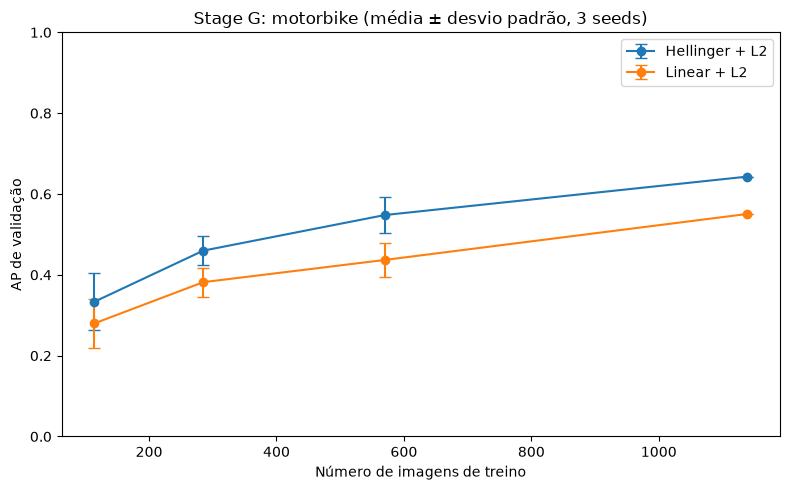

In [13]:
# Reutiliza as representações e o SVM das etapas anteriores.
stage_g_features = {
    "Linear + L2": [l2norm(raw) for raw in (stage_e_train, stage_e_val)],
    "Hellinger + L2": [l2norm(raw) for raw in stage_f_sqrt],
}
stage_g_rows = []
for stage_g_seed in (42, 43, 44):
    stage_g_rng = np.random.default_rng(stage_g_seed)
    # Mantém as proporções das classes e subconjuntos crescentes.
    stage_g_groups = [
        stage_g_rng.permutation(np.flatnonzero(stage_e_labels == label))
        for label in (-1, 1)
    ]
    for stage_g_fraction in (0.1, 0.25, 0.5, 1.0):
        stage_g_indices = np.concatenate([
            group[:int(np.ceil(stage_g_fraction * len(group)))]
            for group in stage_g_groups
        ])
        for stage_g_method, (stage_g_train, stage_g_val) in stage_g_features.items():
            # Usa as mesmas imagens nos dois métodos.
            stage_g_clf = clone(stage_e_clf)
            stage_g_clf.fit(stage_g_train[stage_g_indices], stage_e_labels[stage_g_indices])
            stage_g_scores = stage_g_clf.decision_function(stage_g_val)
            stage_g_rows.append({
                "method": stage_g_method, "fraction": stage_g_fraction,
                "seed": stage_g_seed, "n_train": len(stage_g_indices),
                "n_positive": int(np.sum(stage_e_labels[stage_g_indices] > 0)),
                "val_AP": average_precision_score(stage_e_val_labels, stage_g_scores),
                "svm_iterations": int(stage_g_clf.n_iter_),
                "converged": stage_g_clf.n_iter_ < stage_g_clf.max_iter,
            })

stage_g_results = pd.DataFrame(stage_g_rows)
stage_g_summary = stage_g_results.groupby(
    ["method", "fraction", "n_train", "n_positive"], as_index=False
).agg(val_AP_mean=("val_AP", "mean"), val_AP_std=("val_AP", "std"),
      converged=("converged", "all"))
display(stage_g_summary.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
for stage_g_method, stage_g_group in stage_g_summary.groupby("method"):
    ax.errorbar(stage_g_group["n_train"], stage_g_group["val_AP_mean"],
                yerr=stage_g_group["val_AP_std"], marker="o", capsize=4,
                label=stage_g_method)
ax.set(xlabel="Número de imagens de treino", ylabel="AP de validação",
       title=f"Stage G: {category} (média ± desvio padrão, 3 seeds)", ylim=(0, 1))
ax.legend()
fig.tight_layout()
plt.show()


# Part 2

## Stage H - Vlad

Trainning Histograms shape:  (1139, 10240)
Validation Historgrams shape:  (1202, 10240)


/home/luis/Desktop/iacv_labs/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


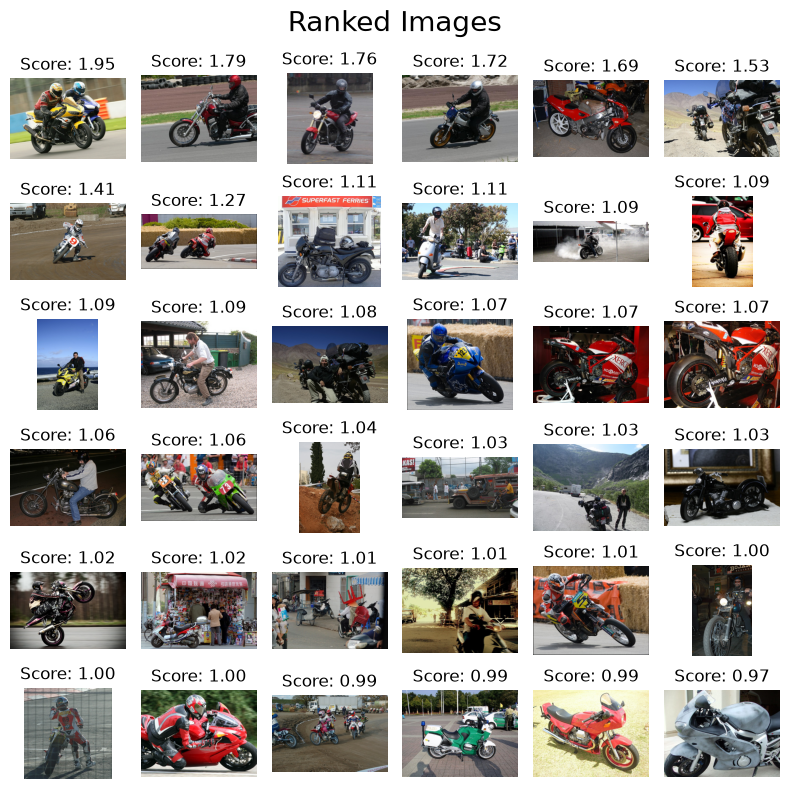

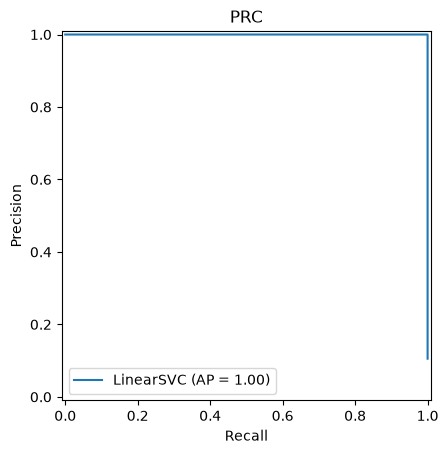

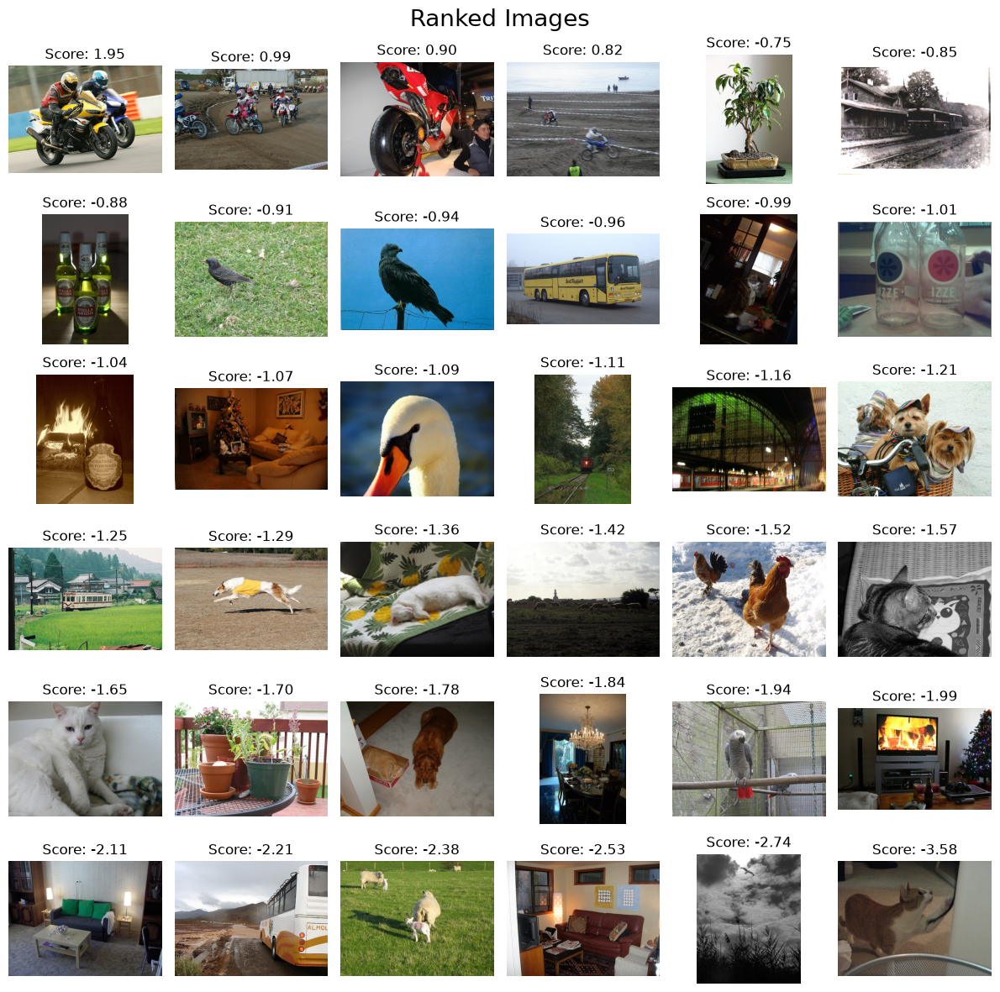

In [21]:
encoding = "vlad_K32_C80"
histograms, labels, names = loadEncodingSubset(category,encoding, subset="train")
testHistograms,testLabels,testNames = loadEncodingSubset(category,encoding,subset="val")

histograms, names, labels = get_subset(histograms,names,labels, np.inf)
histograms = l2norm(histograms)
testHistograms = l2norm(testHistograms)
print("Trainning Histograms shape: ", histograms.shape)
print("Validation Historgrams shape: ", testHistograms.shape)

W, b = utils.train_svm(histograms, labels, C = 10, max_iter=10, tol = 1.0, seed = 42)

scores = (W @ histograms.T + b)
full_paths  = [f"data/images/{name}.jpg" for name in names]
displayRankedImageList(scores, full_paths, uniform=False, figzize=(8,8))
_ = displayPrecisionRecallCurve(labels, scores=scores, title="PRC")

displayRankedImageList(scores, full_paths, uniform = True, figzize=(12,12))
max_idx = np.argmax(scores)
img_file = f"data/images/{names[max_idx]}.jpg"

Avaliação do svm em vlad nos dados de validação

Correctly retrieved in the top 36: 31


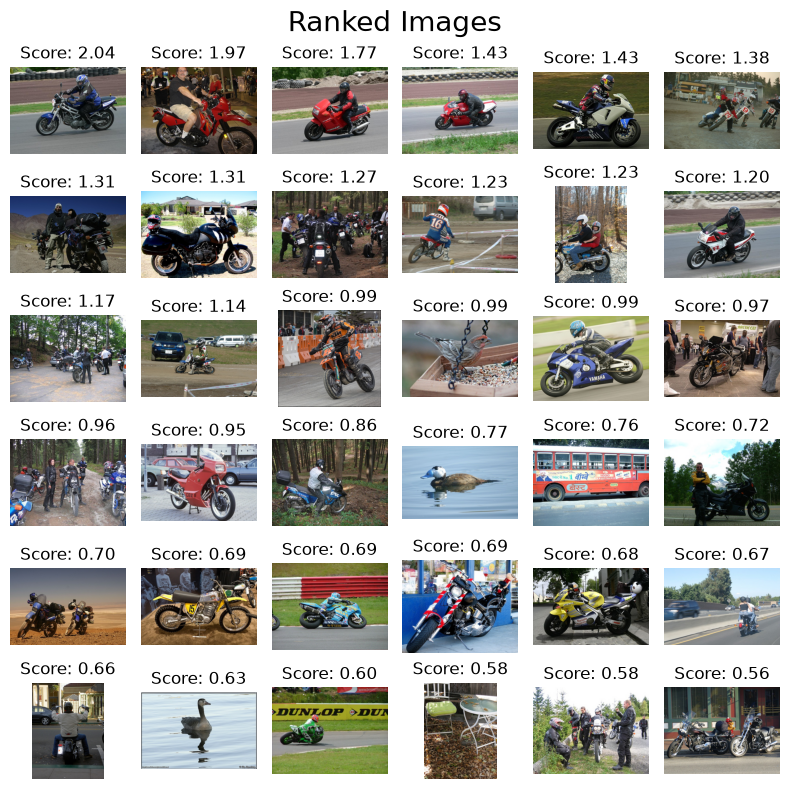

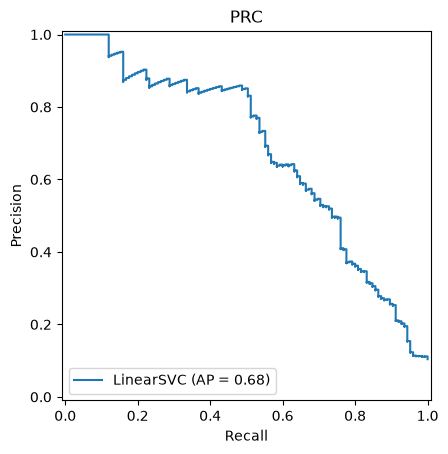

Average Precision (AP)  on test data: 0.6768895110496602
Limiar: 0; ordem: [-1, +1]
Matriz de confusão:
 [[1054   23]
 [  58   67]]
Precisão: 0.7444
Recall: 0.5360


In [24]:
testScores = W @ testHistograms.T + b
perm = np.argsort(testScores)[::-1]
print("Correctly retrieved in the top 36: {:d}".format(sum(testLabels[perm[:36]]>0)))
full_paths = [f"data/images/{name}.jpg" for name in testNames]
displayRankedImageList(testScores, full_paths, uniform=False, figzize=(8,8))
*_, ap = displayPrecisionRecallCurve(testLabels, testScores, title="PRC")
print(f"Average Precision (AP)  on test data: {ap}")
displayClassificationMetrics(testLabels, testScores)

**Consideracoes**: O Vlad tem ... 

## Stage I - Fisher Vector

In [ ]:
encoding = "fv_K32_C80"
histograms, labels, names = loadEncodingSubset(category,encoding, subset="train")
testHistograms,testLabels,testNames = loadEncodingSubset(category,encoding,subset="val")

histograms, names, labels = get_subset(histograms,names,labels, np.inf)
histograms = l2norm(histograms)
testHistograms = l2norm(testHistograms)
print("Trainning Histograms shape: ", histograms.shape)
print("Validation Historgrams shape: ", testHistograms.shape)

W, b = utils.train_svm(histograms, labels, c = None, max_iter=None, tol = None, seed = None)

scores = (W @ histograms.T + b)
full_paths  = [f"data/images/{name}.jpg" for name in names]
displayRankedImageList(scores, full_paths, uniform=False, figzize=(8,8))
_ = displayPrecisionRecallCurve(labels, scores=scores, title="PRC")

displayRankedImageList(scores, full_paths, uniform = True, figzize=(12,12))
max_idx = np.argmax(scores)
img_file = f"data/images/{names[max_idx]}.jpg"

In [ ]:
## Aval do Fisher Vector
testScores = W @ testHistograms.T + b
perm = np.argsort(testScores)[::-1]
print("Correctly retrieved in the top 36: {:d}".format(sum(testLabels[perm[:36]]>0)))
full_paths = [f"data/images/{name}.jpg" for name in testNames]
displayRankedImageList(testScores, full_paths, uniform=False, figzize=(8,8))
*_, ap = displayPrecisionRecallCurve(testLabels, testScores, title="PRC")
print(f"Average Precision (AP)  on test data: {ap:.4.f}")
displayClassificationMetrics(testLabels, testScores)

**Consideracoes**: O Fisher Vector...

In [23]:
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score
from sklearn.svm import LinearSVC

# Run the notebook from code/ so these relative paths resolve.
categories = ("motorbike", "aeroplane", "person", "horse", "car")
encodings = ("bovw_K512_C0", "vlad_K32_C80", "fv_K32_C80")

C_VALUE = 10.0  # Match the Part 1 SVM setting.
MAX_ITER = 200_000
TOL = 1e-4
SEED = 42

rows = []

for encoding_name in encodings:
    for category_name in categories:
        # The assignment data provides train and val splits.
        x_train, y_train, _ = loadEncodingSubset(
            category_name, encoding_name, subset="train", root_dir="data"
        )
        x_val, y_val, _ = loadEncodingSubset(
            category_name, encoding_name, subset="val", root_dir="data"
        )

        # Apply the same normalization to each representation.
        x_train = l2norm(x_train)
        x_val = l2norm(x_val)

        clf = LinearSVC(
            C=C_VALUE,
            loss="hinge",
            dual=True,
            max_iter=MAX_ITER,
            tol=TOL,
            random_state=SEED,
        )

        start = perf_counter()
        clf.fit(x_train, y_train)
        fit_seconds = perf_counter() - start

        start = perf_counter()
        val_scores = clf.decision_function(x_val)
        inference_seconds = perf_counter() - start

        ap = average_precision_score(y_val, val_scores, pos_label=1)

        rows.append({
            "encoding": encoding_name,
            "category": category_name,
            "AP (validation)": ap,
            "feature dimension": x_train.shape[1],
            "SVM fit (s)": fit_seconds,
            "validation scoring (ms/image)": (
                1000 * inference_seconds / len(y_val)
            ),
        })

results = pd.DataFrame(rows)

# Per-class AP, plus mean AP across the selected categories.
map_rows = (
    results.groupby("encoding", as_index=False)
    .agg(
        **{
            "mAP (validation)": ("AP (validation)", "mean"),
            "feature dimension": ("feature dimension", "first"),
            "mean SVM fit (s)": ("SVM fit (s)", "mean"),
            "mean scoring (ms/image)": (
                "validation scoring (ms/image)", "mean"
            ),
        }
    )
)

display(results.round(4))
display(map_rows.round(4))

,encoding,category,AP (validation),feature dimension,SVM fit (s),validation scoring (ms/image)
0,bovw_K512_C0,motorbike,0.5506,2048,1.8446,0.0045
1,bovw_K512_C0,aeroplane,0.5270,2048,0.8336,0.0031
2,bovw_K512_C0,person,0.7003,2048,3.3262,0.0033
3,bovw_K512_C0,horse,0.5692,2048,2.0931,0.0044
4,bovw_K512_C0,car,0.6716,2048,4.5879,0.0040
5,vlad_K32_C80,motorbike,0.6632,10240,1.7701,0.0203
6,vlad_K32_C80,aeroplane,0.7136,10240,1.0367,0.0203
7,vlad_K32_C80,person,0.7449,10240,14.1172,0.0432
8,vlad_K32_C80,horse,0.9625,10240,1.2398,0.0234
9,vlad_K32_C80,car,0.9907,10240,2.2571,0.0550


,encoding,mAP (validation),feature dimension,mean SVM fit (s),mean scoring (ms/image)
0,bovw_K512_C0,0.6037,2048,2.5371,0.0039
1,fv_K32_C80,0.7258,20608,42.1828,0.0238
2,vlad_K32_C80,0.8150,10240,4.0842,0.0324
